<a href="https://colab.research.google.com/github/danielolafisoye/WildlifeReID-10k-Comparison/blob/main/MiewID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd
import kagglehub

# Safely resolve the dataset download directory path
try:
    resolved_path = dataset_path
except NameError:
    resolved_path = kagglehub.dataset_download("wildlifedatasets/wildlifereid-10k")

# 1. List files in the downloaded directory to find metadata
files = os.listdir(resolved_path)
print("Files and folders in dataset:", files)

# 2. Look for CSV files
csv_files = [f for f in files if f.endswith('.csv')]
print("Found CSV files:", csv_files)

# 3. Load the primary metadata file if it exists
for csv_file in csv_files:
    csv_path = os.path.join(resolved_path, csv_file)
    df = pd.read_csv(csv_path)
    print(f"\nMetadata Summary for {csv_file}:")
    print(df.info())
    display(df.head())

Files and folders in dataset: ['citation', 'metadata.csv', 'citation.pdf', 'images']
Found CSV files: ['metadata.csv']

Metadata Summary for metadata.csv:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140488 entries, 0 to 140487
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   identity     140488 non-null  object
 1   path         140488 non-null  object
 2   date         47852 non-null   object
 3   orientation  50517 non-null   object
 4   species      140488 non-null  object
 5   split        140488 non-null  object
 6   dataset      140488 non-null  object
 7   cluster_id   72609 non-null   object
dtypes: object(8)
memory usage: 8.6+ MB
None


/tmp/ipykernel_612/1069910716.py:22: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


,identity,path,date,orientation,species,split,dataset,cluster_id
0,AAUZebraFish_5,images/AAUZebraFish/data/Vid2_0520_0000ef3f3f3...,NaN,right,fish,train,AAUZebraFish,AAUZebraFish_5_0
1,AAUZebraFish_3,images/AAUZebraFish/data/Vid1_0062_0002c4ff6de...,NaN,right,fish,train,AAUZebraFish,NaN
2,AAUZebraFish_4,images/AAUZebraFish/data/Vid2_1065_000444965a5...,NaN,right,fish,test,AAUZebraFish,NaN
3,AAUZebraFish_6,images/AAUZebraFish/data/Vid2_0381_001446b650f...,NaN,right,fish,train,AAUZebraFish,NaN
4,AAUZebraFish_2,images/AAUZebraFish/data/Vid1_0582_00173b45939...,NaN,left,fish,test,AAUZebraFish,NaN


In [ ]:
import numpy as np

Available subfolders under images: ['FriesianCattle2015', 'CZoo', 'MPDD', 'NDD20', 'DogFaceNet', 'LeopardID2022', 'NyalaData', 'CTai', 'SealID', 'CowDataset'] ... (Total: 37)

Displaying images from subfolder: FriesianCattle2015


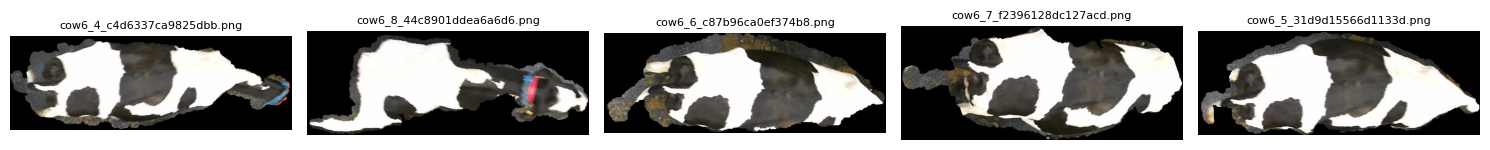

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# 1. Locate the image directory
images_dir = os.path.join(path, "images")

if os.path.exists(images_dir):
    # 2. List subfolders (representing different categories/datasets/species)
    subfolders = [d for d in os.listdir(images_dir) if os.path.isdir(os.path.join(images_dir, d))]
    print("Available subfolders under images:", subfolders[:10], f"... (Total: {len(subfolders)})")

    if subfolders:
        # Let's take the first subfolder
        selected_subfolder = subfolders[0]
        selected_dir = os.path.join(images_dir, selected_subfolder)
        print(f"\nDisplaying images from subfolder: {selected_subfolder}")

        # Find up to 5 image files in this subfolder recursively or directly
        img_paths = []
        for root, _, files in os.walk(selected_dir):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    img_paths.append(os.path.join(root, file))
                    if len(img_paths) >= 5:
                        break
            if len(img_paths) >= 5:
                break

        # 3. Plot the images
        if img_paths:
            fig, axes = plt.subplots(1, len(img_paths), figsize=(15, 5))
            if len(img_paths) == 1:
                axes = [axes]
            for ax, img_p in zip(axes, img_paths):
                img = Image.open(img_p)
                ax.imshow(img)
                ax.axis('off')
                ax.set_title(os.path.basename(img_p), fontsize=8)
            plt.tight_layout()
            plt.show()
        else:
            print("No images found in the selected subfolder.")
else:
    print("Images directory not found at:", images_dir)

In [ ]:
!pip install -q transformers timm

In [ ]:
import torch

In [ ]:
import torch
from transformers import AutoModel, AutoConfig

# Get the custom model class from the remote repository config first
config = AutoConfig.from_pretrained("conservationxlabs/miewid-msv3", trust_remote_code=True)
model_class = AutoModel._model_mapping[type(config)]

# Patch the class dynamically to support 'all_tied_weights_keys'
if not hasattr(model_class, "all_tied_weights_keys"):
    model_class.all_tied_weights_keys = property(lambda self: {})

device = "cuda" if torch.cuda.is_available() else "cpu"

# Now load the model safely
model = AutoModel.from_pretrained(
    "conservationxlabs/miewid-msv3",
    trust_remote_code=True
).to(device).eval()


Building Model Backbone for efficientnetv2_rw_m model
config.model_name efficientnetv2_rw_m
model_name efficientnetv2_rw_m


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:2589: UserWarning: for conv_stem.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  module._load_from_state_dict(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/batchnorm.py:133: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  super()._load_from_state_dict(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/batchnorm.py:133: UserWarning: for bn1.bias: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model,

final_in_features 2152


Loading weights:   0%|          | 0/1210 [00:00<?, ?it/s]

In [ ]:
import os
import torchvision.transforms as T
from PIL import Image
import kagglehub

# Re-fetch or locate the dataset directory safely
try:
    dataset_path = path
except NameError:
    # kagglehub.dataset_download is fast if the dataset is already cached locally
    dataset_path = kagglehub.dataset_download("wildlifedatasets/wildlifereid-10k")

# Define the preprocessing steps
preprocess = T.Compose([
    T.Resize((440, 440)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Find a real image from our downloaded dataset instead of the placeholder 'some_image.jpg'
images_dir = os.path.join(dataset_path, "images")
real_image_path = None

for root, _, files in os.walk(images_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            real_image_path = os.path.join(root, file)
            break
    if real_image_path:
        break

if real_image_path:
    print(f"Using image: {real_image_path}")
    img = Image.open(real_image_path).convert("RGB")
    x = preprocess(img).unsqueeze(0).to(device)

    with torch.no_grad():
        emb = model(x)                       # shape: (1, embedding_dim)
        emb = torch.nn.functional.normalize(emb, dim=1)
    print("Embedding shape:", emb.shape)
else:
    print("No image file found in the dataset folder.")

100%|██████████| 24.5G/24.5G [06:13<00:00, 70.5MB/s]

Extracting files...


Using image: /root/.cache/kagglehub/datasets/wildlifedatasets/wildlifereid-10k/versions/10/images/HyenaID2022/hyena.coco/images/train2022/000000001433_1453.jpg
Embedding shape: torch.Size([1, 2152])


In [ ]:
import pandas as pd, os
# Use the verified 'dataset_path' variable from the active kernel state
print(os.listdir(dataset_path))
df = pd.read_csv(os.path.join(dataset_path, "metadata.csv"))
print(df.columns.tolist())
print(df.head())
print(df["split"].value_counts())

['citation', 'metadata.csv', 'citation.pdf', 'images']
['identity', 'path', 'date', 'orientation', 'species', 'split', 'dataset', 'cluster_id']
         identity                                               path date  \
0  AAUZebraFish_5  images/AAUZebraFish/data/Vid2_0520_0000ef3f3f3...  NaN   
1  AAUZebraFish_3  images/AAUZebraFish/data/Vid1_0062_0002c4ff6de...  NaN   
2  AAUZebraFish_4  images/AAUZebraFish/data/Vid2_1065_000444965a5...  NaN   
3  AAUZebraFish_6  images/AAUZebraFish/data/Vid2_0381_001446b650f...  NaN   
4  AAUZebraFish_2  images/AAUZebraFish/data/Vid1_0582_00173b45939...  NaN   

  orientation species  split       dataset        cluster_id  
0       right    fish  train  AAUZebraFish  AAUZebraFish_5_0  
1       right    fish  train  AAUZebraFish               NaN  
2       right    fish   test  AAUZebraFish               NaN  
3       right    fish  train  AAUZebraFish               NaN  
4        left    fish   test  AAUZebraFish               NaN  
split
train    

/tmp/ipykernel_612/2652073549.py:4: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(os.path.join(dataset_path, "metadata.csv"))


In [ ]:
df.columns

Index(['identity', 'path', 'date', 'orientation', 'species', 'split',
       'dataset', 'cluster_id'],
      dtype='object')

In [ ]:
df.head()

,identity,path,date,orientation,species,split,dataset,cluster_id
0,AAUZebraFish_5,images/AAUZebraFish/data/Vid2_0520_0000ef3f3f3...,NaN,right,fish,train,AAUZebraFish,AAUZebraFish_5_0
1,AAUZebraFish_3,images/AAUZebraFish/data/Vid1_0062_0002c4ff6de...,NaN,right,fish,train,AAUZebraFish,NaN
2,AAUZebraFish_4,images/AAUZebraFish/data/Vid2_1065_000444965a5...,NaN,right,fish,test,AAUZebraFish,NaN
3,AAUZebraFish_6,images/AAUZebraFish/data/Vid2_0381_001446b650f...,NaN,right,fish,train,AAUZebraFish,NaN
4,AAUZebraFish_2,images/AAUZebraFish/data/Vid1_0582_00173b45939...,NaN,left,fish,test,AAUZebraFish,NaN


In [20]:
print(df["split"].value_counts())
print(df["species"].value_counts())
print(df["identity"].nunique())

split
train    109927
test      30561
Name: count, dtype: int64
species
cow           23465
sea turtle    22709
cat           13021
dog           10020
whale          8559
zebra          8374
whaleshark     7693
chimpanzee     6974
panda          6874
leopard        6806
tiger          5415
hyena          3129
dolphin        2657
bird           2629
sea star       2187
seal           2080
giraffe        2002
nyala          1942
polar bear     1391
chicken        1146
macaque        1079
fish            336
Name: count, dtype: int64
10772
